# Pathfinding Agent: A* vs Dijkstra
Grid: `0` = free cell, `1` = wall. The agent moves up / down / left / right from START to GOAL.

In [1]:
import heapq
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right

## 1. Helper functions

In [2]:
def get_neighbors(grid, cell):
    """Free cells next to `cell` (inside the grid, not a wall)."""
    result = []
    for dr, dc in MOVES:
        r, c = cell[0] + dr, cell[1] + dc
        if 0 <= r < len(grid) and 0 <= c < len(grid[0]) and grid[r][c] == 0:
            result.append((r, c))
    return result


def build_path(parent, goal):
    """Walk back from goal to start using the parent dictionary."""
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = parent[cell]
    return path[::-1]

## 2. Dijkstra's algorithm
Always expands the cell with the lowest cost from the start. It has no idea where the goal is.

In [3]:
def dijkstra(grid, start, goal):
    queue = [(0, start)]          # (cost so far, cell)
    cost = {start: 0}
    parent = {start: None}
    expanded = set()

    while queue:
        _, cell = heapq.heappop(queue)
        if cell in expanded:
            continue
        expanded.add(cell)

        if cell == goal:
            return build_path(parent, goal), expanded

        for nb in get_neighbors(grid, cell):
            new_cost = cost[cell] + 1
            if nb not in cost or new_cost < cost[nb]:
                cost[nb] = new_cost
                parent[nb] = cell
                heapq.heappush(queue, (new_cost, nb))

    return None, expanded         # no path found

## 3. A* search
Same as Dijkstra, but priority = cost so far + heuristic. The heuristic is the Manhattan distance to the goal, so A* prefers cells that are closer to the goal.

In [4]:
def heuristic(cell, goal):
    return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])


def a_star(grid, start, goal):
    # (cost + heuristic, heuristic, cell). 
    # The 2nd value breaks ties: closer to goal goes first.
    
    queue = [(heuristic(start, goal), heuristic(start, goal), start)]
    cost = {start: 0}
    parent = {start: None}
    expanded = set()

    while queue:
        _, _, cell = heapq.heappop(queue)
        if cell in expanded:
            continue
        expanded.add(cell)

        if cell == goal:
            return build_path(parent, goal), expanded

        for nb in get_neighbors(grid, cell):
            new_cost = cost[cell] + 1
            if nb not in cost or new_cost < cost[nb]:
                cost[nb] = new_cost
                parent[nb] = cell
                h = heuristic(nb, goal)
                heapq.heappush(queue, (new_cost + h, h, nb))

    return None, expanded

## 4. Three test grids (20x20 with 10%, 20% and 30% obstacles)

In [5]:
SIZE = 20
START, GOAL = (0, 0), (SIZE - 1, SIZE - 1)


def make_grid(density, seed):
    """Random grid. A new seed is tried 
    until a path from START to GOAL exists."""
    
    while True:
        rng = np.random.default_rng(seed)
        grid = (rng.random((SIZE, SIZE)) < density).astype(int)
        grid[START] = 0
        grid[GOAL] = 0
        if dijkstra(grid.tolist(), START, GOAL)[0] is not None:
            return grid.tolist()
        seed += 1


grids = {
    "Grid 1 (10% obstacles)": make_grid(0.10, seed=1),
    "Grid 2 (20% obstacles)": make_grid(0.20, seed=2),
    "Grid 3 (30% obstacles)": make_grid(0.30, seed=3),
}

## 5. Run both algorithms and record the metrics
- **Steps**: number of moves in the final path
- **Expanded nodes**: how many cells the algorithm explored
- **Expansion density**: expanded nodes as % of all free cells
- **Runtime**: average of 50 runs (a single run is too fast to measure)

In [6]:
def run(algorithm, grid):
    t0 = time.perf_counter()
    for _ in range(50):
        path, expanded = algorithm(grid, START, GOAL)
    runtime_ms = (time.perf_counter() - t0) / 50 * 1000

    free_cells = sum(row.count(0) for row in grid)
    return {
        "steps": len(path) - 1,
        "expanded_nodes": len(expanded),
        "expansion_density_%": round(100 * len(expanded) / free_cells, 1),
        "runtime_ms": round(runtime_ms, 3),
    }, path, expanded


rows = []
saved = {}   # keep path and expanded cells for plotting
for grid_name, grid in grids.items():
    for algo_name, algo in [("Dijkstra", dijkstra), ("A*", a_star)]:
        metrics, path, expanded = run(algo, grid)
        rows.append({"grid": grid_name, "algorithm": algo_name, **metrics})
        saved[(grid_name, algo_name)] = (path, expanded)

results = pd.DataFrame(rows)
results

,grid,algorithm,steps,expanded_nodes,expansion_density_%,runtime_ms
0,Grid 1 (10% obstacles),Dijkstra,38,359,100.0,11.128
1,Grid 1 (10% obstacles),A*,38,95,26.5,1.371
2,Grid 2 (20% obstacles),Dijkstra,38,319,99.7,13.939
3,Grid 2 (20% obstacles),A*,38,51,15.9,2.305
4,Grid 3 (30% obstacles),Dijkstra,38,292,98.3,4.729
5,Grid 3 (30% obstacles),A*,38,57,19.2,1.060


## 6. Visualize the paths
Light blue = cells explored, red = final path, green = start, yellow = goal. Images are saved in the `outputs` folder.

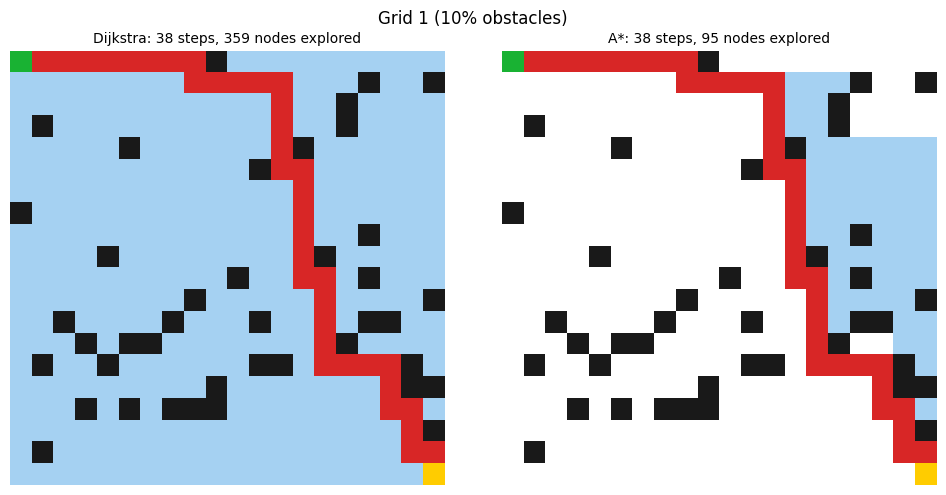

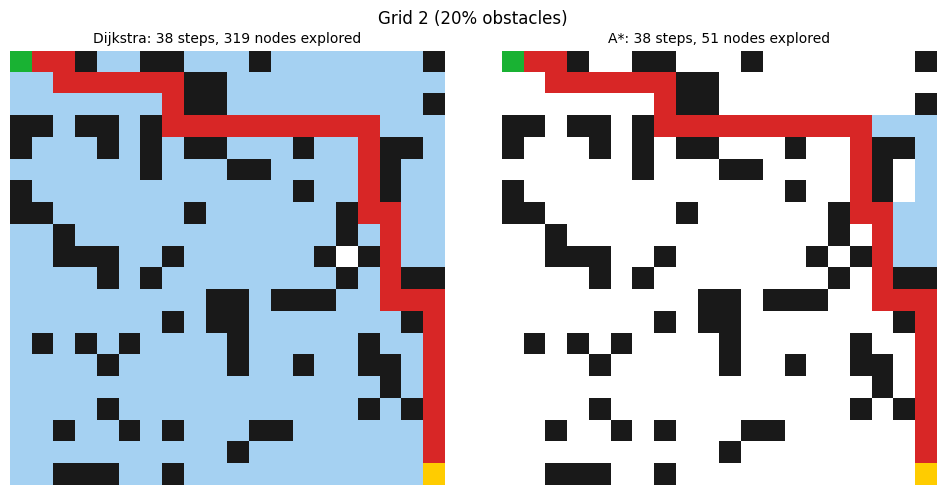

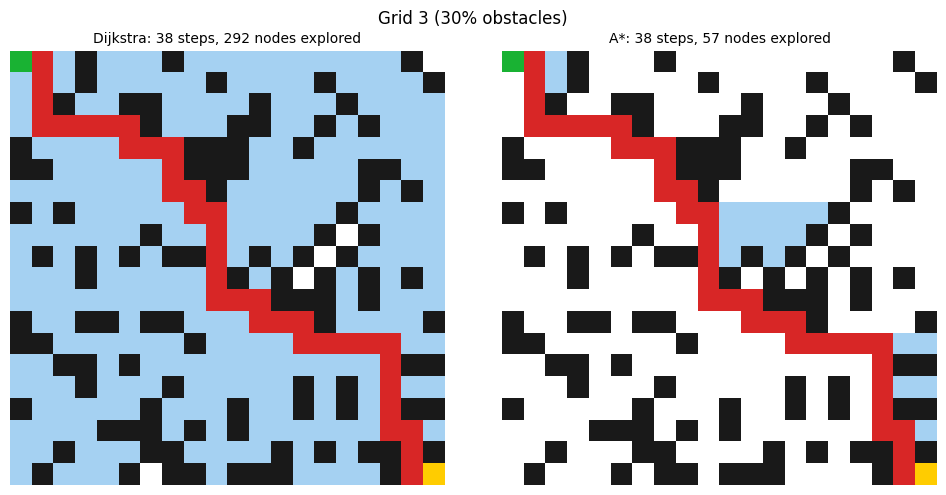

In [ ]:
def draw(ax, grid, path, expanded, title):
    img = np.ones((SIZE, SIZE, 3))
    img[np.array(grid) == 1] = (0.1, 0.1, 0.1)      # walls
    for cell in expanded:
        img[cell] = (0.65, 0.82, 0.95)               # explored
    for cell in path:
        img[cell] = (0.85, 0.15, 0.15)               # path
    img[START] = (0.1, 0.7, 0.2)
    img[GOAL] = (1.0, 0.8, 0.0)
    ax.imshow(img)
    ax.set_title(title, fontsize=10)
    ax.axis("off")


for i, (grid_name, grid) in enumerate(grids.items(), start=1):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, algo_name in zip(axes, ["Dijkstra", "A*"]):
        path, expanded = saved[(grid_name, algo_name)]
        draw(ax, grid, path, expanded,
             f"{algo_name}: {len(path) - 1} steps, {len(expanded)} nodes explored")
        
    fig.suptitle(grid_name)
    plt.tight_layout()
    fig.savefig(f"outputs/grid_{i}_paths.png", dpi=110)
    plt.show()

## 7. Export results

In [8]:
results.to_csv("outputs/results.csv", index=False)

with open("outputs/log.txt", "w") as f:
    for grid_name in grids:
        f.write(f"{grid_name}\n")
        for algo_name in ["Dijkstra", "A*"]:
            path, expanded = saved[(grid_name, algo_name)]
            f.write(f"  {algo_name}: steps={len(path) - 1}, expanded={len(expanded)}\n")
            f.write(f"  path: {path}\n")
        f.write("\n")

print("Saved: outputs/results.csv, outputs/log.txt, outputs/grid_*_paths.png")

Saved: outputs/results.csv, outputs/log.txt, outputs/grid_*_paths.png
